# Chapter 2 problem set — From one perceptron to networks

| | |
| --- | --- |
| **Prerequisites** | Notebooks 07–12 |
| **Covers** | Hand-constructed step networks, second-order optimization of logistic regression, a silent data bug in multiclass training, constructed versus trained ReLU networks, an independent diagnostic study |
| **Estimated time** | 5–7 hours |
| **Compute** | CPU |

These problems combine ideas from the whole chapter. Each has automated checks; problems 2, 4, and 5 also ask for a short written analysis. Attempt each problem before opening its hint.

## Setup

In [1]:
# Setup: make the course helpers importable and record the environment.
import sys
from pathlib import Path

try:
    import dlcourse
except ImportError:  # running without `uv sync`, e.g. on Colab after cloning the repo
    root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "dlcourse").is_dir())
    sys.path.insert(0, str(root))
    import dlcourse

import matplotlib.pyplot as plt
import torch

from dlcourse import check, check_close, check_shape, passed, set_seed
from dlcourse.plotting import setup_style

setup_style()
device = dlcourse.describe_environment()
set_seed(0)

Python  3.12.13 (Darwin arm64)
PyTorch 2.14.1
CUDA available: False
MPS available:  True
Selected device: cpu


In [2]:
import math

import torch.nn as nn
import torch.nn.functional as F

from dlcourse.data import make_blobs, make_checkerboard
from dlcourse.plotting import COLORS, plot_dataset, plot_decision_boundary

## Problem 1: A 16-tile checkerboard from step units

*Notebooks 08 and 11.* `make_checkerboard(tiles=4)` colors the square $[-1, 1]^2$ like a 4×4 checkerboard. Each tile is $0.5 \times 0.5$, and a point's class is the parity of its tile's column index plus its row index:

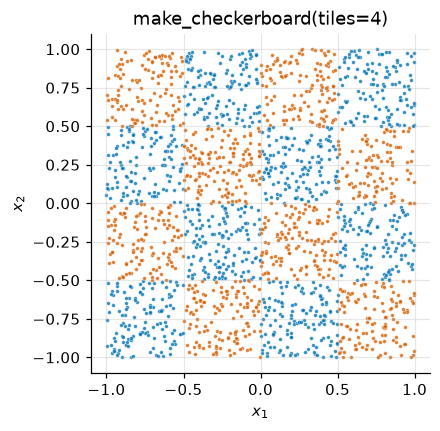

In [3]:
X_board, y_board = make_checkerboard(n=2000, tiles=4, seed=0)
plot_dataset(X_board, y_board, title="make_checkerboard(tiles=4)", s=6)
plt.show()

**Your task:** build a network of **step units**, $\operatorname{step}(z) = 1$ if $z \ge 0$ else $0$, that classifies every point correctly. Use exactly this architecture, so that no training is needed — only reasoning:

| Layer | Units | Role |
| --- | --- | --- |
| 1 | 6 | One unit per grid line: $x_1 = -0.5, 0, 0.5$ and $x_2 = -0.5, 0, 0.5$ |
| 2 | 2 | An OR unit and a NAND unit |
| 3 | 1 | An AND unit: the class |

Grid lines belong to the tile on their right/above, matching the generator's floor rule; the outer edge at 1 belongs to the final tile. The non-strict step matters on these boundaries.

Store the layers as `board_layers = [(W1, b1), (W2, b2), (W3, b3)]` with `nn.Linear`'s layout: `W1` is `(6, 2)`, `W2` is `(2, 6)`, `W3` is `(1, 2)`. The function below runs them.

Plan it in two steps:

1. **Column parity.** Let $s_1, s_2, s_3$ be the outputs of the units for $x_1 \ge -0.5$, $x_1 \ge 0$, $x_1 \ge 0.5$. The column index is $i = s_1 + s_2 + s_3$. Because the thresholds are ordered, $s_1 \ge s_2 \ge s_3$. Show that the column parity $i \bmod 2$ equals the **linear** expression $s_1 - s_2 + s_3$. The same holds for rows.
2. **XOR of parities.** The class is $(i + j) \bmod 2 = \operatorname{XOR}(i \bmod 2,\ j \bmod 2)$. Notebook 11 built XOR as AND(OR, NAND). Each of the OR and NAND units reads the two parities — and each parity is a linear combination of layer-1 outputs, so it can be folded into the layer-2 weights.

In [4]:
def step(z):
    return (z >= 0).float()


def run_step_network(X, layers):
    """Apply step(X @ W.T + b) for each (W, b) in layers; return labels of shape (N,)."""
    h = X
    for W, b in layers:
        h = step(h @ W.T + b)
    return h.squeeze(1).long()

<details>
<summary><b>💡 Hint</b></summary>

Layer 1: rows `[1, 0]` with biases `0.5, 0, -0.5` (for $x_1 \ge -0.5$, $x_1 \ge 0$, $x_1 \ge 0.5$), then the same with `[0, 1]`. Layer 2: OR of the parities is `step(cx + cy - 0.5)`, so its weights are `[1, -1, 1, 1, -1, 1]` with bias `-0.5`. NAND is `step(-(cx + cy) + 1.5)`. Layer 3: AND is `step(h1 + h2 - 1.5)`.

</details>

In [5]:
W1 = torch.tensor([[1.0, 0.0], [1.0, 0.0], [1.0, 0.0],
                   [0.0, 1.0], [0.0, 1.0], [0.0, 1.0]])
b1 = torch.tensor([0.5, 0.0, -0.5, 0.5, 0.0, -0.5])
parity = torch.tensor([1.0, -1.0, 1.0, 1.0, -1.0, 1.0])  # cx + cy as a combination of layer-1 outputs
W2 = torch.stack([parity, -parity])                       # OR, NAND
b2 = torch.tensor([-0.5, 1.5])
W3 = torch.tensor([[1.0, 1.0]])                           # AND
b3 = torch.tensor([-1.5])
board_layers = [(W1, b1), (W2, b2), (W3, b3)]

In [6]:
check(len(board_layers) == 3, f"board_layers should have 3 layers, got {len(board_layers)}")
for (W, b), shape in zip(board_layers, [(6, 2), (2, 6), (1, 2)]):
    check_shape(W, shape, "layer weight")
    check_shape(b, (shape[0],), "layer bias")
predictions = run_step_network(X_board, board_layers)
accuracy = (predictions == y_board).float().mean().item()
check(accuracy == 1.0, f"accuracy is {accuracy:.3f}; every point should be classified correctly")
# Include grid lines, their intersections, outer edges, interiors, and nearby points.
coords = torch.tensor([-1.0, -0.75, -0.5001, -0.5, -0.4999, -0.25,
                       -0.0001, 0.0, 0.0001, 0.25, 0.4999, 0.5, 0.5001, 0.75, 1.0])
boundary_points = torch.cartesian_prod(coords, coords)
cells = ((boundary_points + 1) * 2).floor().clamp(0, 3).long()
expected = cells.sum(dim=1) % 2
check(torch.equal(run_step_network(boundary_points, board_layers), expected),
      "checkerboard labels must also agree on grid lines, intersections, and outer edges")
passed("Problem 1")

✅ Problem 1 passed


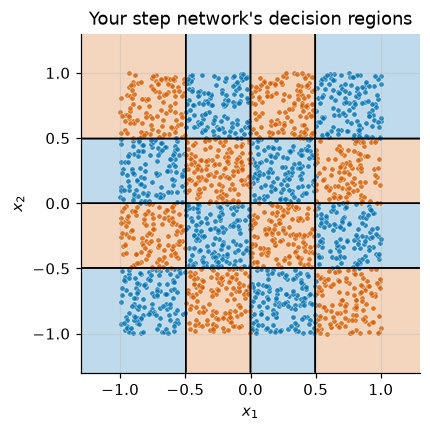

In [7]:
if "board_layers" in globals():
    plot_decision_boundary(lambda P: run_step_network(P, board_layers), X_board, y_board, title="Your step network's decision regions")
    plt.show()

> **Worked solution.**
>
> Column parity: with ordered thresholds, $(s_1, s_2, s_3)$ can only be $(0,0,0), (1,0,0), (1,1,0), (1,1,1)$ for columns $i = 0, 1, 2, 3$. Then $s_1 - s_2 + s_3 = 0, 1, 0, 1$ — exactly $i \bmod 2$. In general, for ordered thresholds the alternating sum is the parity, which is why one linear layer suffices. A step network for an $n \times n$ board needs only $2(n-1)$ first-layer units plus the 3-unit XOR, while the disjunctive-normal-form construction from notebook 11 would need one unit per black tile.

## Problem 2: Newton's method for logistic regression

*Notebooks 03, 06, and 09.* Gradient descent uses only the slope. **Newton's method** also uses the curvature: it fits a quadratic to the loss at the current point and jumps to that quadratic's minimum,

$$\boldsymbol\theta \leftarrow \boldsymbol\theta - H^{-1}\, \nabla L(\boldsymbol\theta),$$

where $H$ is the Hessian. For logistic regression with augmented inputs $\tilde{X}$ (a column of ones appended, so $\boldsymbol\theta = (\mathbf{w}, b)$), notebook 09 derived

$$\nabla L = \tfrac{1}{N}\tilde{X}^\top(\hat{\mathbf p} - \mathbf y), \qquad H = \tfrac{1}{N}\tilde{X}^\top \operatorname{diag}\big(\hat{\mathbf p} \odot (1 - \hat{\mathbf p})\big)\, \tilde{X}.$$

### 2a. Implement it

Write `newton_logistic(X_aug, y, steps)` returning `(theta, losses)`: the final parameters, shape `(D + 1,)`, and the list of binary cross-entropy losses **before** each step. Start from $\boldsymbol\theta = \mathbf 0$. Use `torch.linalg.solve(H, g)` rather than forming $H^{-1}$ explicitly; it is faster and more accurate. Work in `float64`.

In [8]:
X_lr, y_lr = make_blobs(n=200, centers=((-0.6, -0.4), (0.6, 0.5)), std=0.7, seed=3)
X_aug = torch.cat([X_lr, torch.ones(len(X_lr), 1)], dim=1).double()  # (400, 3)
y_lr = y_lr.double()

<details>
<summary><b>💡 Hint</b></summary>

In each step: `p = torch.sigmoid(X_aug @ theta)`, record the loss with `F.binary_cross_entropy(p, y)`, form `g = X_aug.T @ (p - y) / N` and `H = (X_aug * (p * (1 - p)).unsqueeze(1)).T @ X_aug / N`, then `theta = theta - torch.linalg.solve(H, g)`. Multiplying the rows of `X_aug` by the weights is the same as the `diag(...)` product, without building an `N × N` matrix.

</details>

In [9]:
def newton_logistic(X_aug, y, steps=10):
    n = len(y)
    theta = torch.zeros(X_aug.shape[1], dtype=X_aug.dtype)
    losses = []
    for _ in range(steps):
        p = torch.sigmoid(X_aug @ theta)
        losses.append(F.binary_cross_entropy(p, y).item())
        g = X_aug.T @ (p - y) / n
        H = (X_aug * (p * (1 - p)).unsqueeze(1)).T @ X_aug / n
        theta = theta - torch.linalg.solve(H, g)
    return theta, losses

In [10]:
theta_newton, newton_losses = newton_logistic(X_aug, y_lr, steps=10)
check_shape(theta_newton, (3,), "theta from newton_logistic")
check(len(newton_losses) == 10, f"expected 10 recorded losses, got {len(newton_losses)}")
p_final = torch.sigmoid(X_aug @ theta_newton)
gradient = X_aug.T @ (p_final - y_lr) / len(y_lr)
check(gradient.abs().max().item() < 1e-10, f"gradient at the result is {gradient.abs().max().item():.2e}; Newton's method should reach ~0 in 10 steps")
reference = nn.Linear(2, 1).double()
optimizer = torch.optim.LBFGS(reference.parameters(), max_iter=200, tolerance_grad=1e-12, tolerance_change=1e-14)
def closure():
    optimizer.zero_grad()
    loss = F.binary_cross_entropy_with_logits(reference(X_aug[:, :2]).squeeze(1), y_lr)
    loss.backward()
    return loss
optimizer.step(closure)
check_close(theta_newton, torch.cat([reference.weight.detach().squeeze(0), reference.bias.detach()]), "theta vs an L-BFGS reference", atol=1e-6)
passed("Problem 2a")

✅ Problem 2a passed


### 2b. Investigate: how fast is Newton's method?

The cell below runs gradient descent with the largest safe fixed learning rate, $\eta = 1/\lambda_{\max}$ of the Hessian at $\boldsymbol\theta = \mathbf 0$ (where it is largest, since $\hat p(1-\hat p) \le 1/4$), and plots both methods' **loss gap** — loss minus the optimal loss — against the iteration number. Run it, then answer in the markdown cell below:

1. Describe each curve's shape on the log scale. How many steps does each need to reach a gap of $10^{-12}$?
2. Count the arithmetic per step for $D$ parameters and $N$ examples: forming $H$, and solving with it. Why is Newton's method not used to train networks with millions of parameters?
3. What would happen to Newton's method on **perfectly separable** data (notebook 09, section 7)?

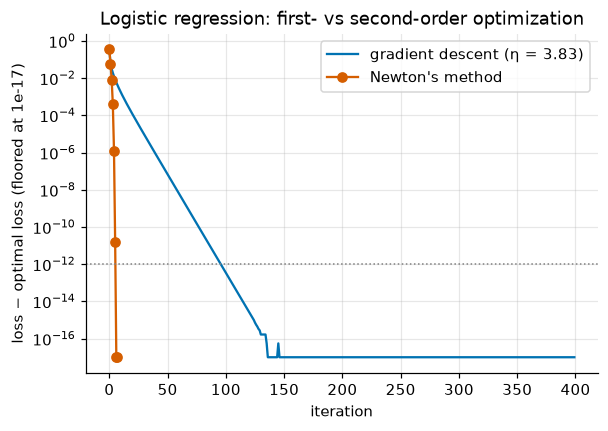

gradient descent : first iteration with gap < 1e-12: 96
Newton           : first iteration with gap < 1e-12: 6


In [11]:
best_loss = min(newton_losses)
theta_gd = torch.zeros(3, dtype=torch.float64)
H0 = X_aug.T @ X_aug * 0.25 / len(y_lr)
lr_gd = 1.0 / torch.linalg.eigvalsh(H0).max().item()
gd_gaps = []
for _ in range(400):
    p = torch.sigmoid(X_aug @ theta_gd)
    gd_gaps.append(F.binary_cross_entropy(p, y_lr).item() - best_loss)
    theta_gd -= lr_gd * X_aug.T @ (p - y_lr) / len(y_lr)

_, long_newton = newton_logistic(X_aug, y_lr, steps=8)
newton_gaps = [loss - best_loss for loss in long_newton]
plt.semilogy([max(g, 1e-17) for g in gd_gaps], label=f"gradient descent (η = {lr_gd:.2f})")
plt.semilogy([max(g, 1e-17) for g in newton_gaps], "o-", label="Newton's method")
plt.axhline(1e-12, color="gray", ls=":", lw=1)
plt.xlabel("iteration")
plt.ylabel("loss − optimal loss (floored at 1e-17)")
plt.title("Logistic regression: first- vs second-order optimization")
plt.legend()
plt.show()
for name, gaps in [("gradient descent", gd_gaps), ("Newton", newton_gaps)]:
    reached = next((i for i, g in enumerate(gaps) if g < 1e-12), None)
    print(f"{name:17s}: first iteration with gap < 1e-12: {reached}")

*Your answers:*

> **Worked solution.**
>
> 1. Gradient descent's gap falls along a straight line on the log scale: **linear convergence**, a constant factor per step, set by the condition number of the Hessian (notebook 03). It needs about a hundred iterations to reach 1e-12 here. Newton's curve bends downward ever more steeply: **quadratic convergence** — once close, the number of correct digits roughly doubles each step — and it reaches 1e-12 in 6 iterations, against 96 for gradient descent. Points that hit the rounding floor are drawn at 1e-17.
> 2. Forming $H = \tilde X^\top \operatorname{diag}(\cdot)\tilde X$ costs about $N D^2$ operations and $D^2$ memory; solving costs about $D^3/3$. A gradient step costs about $N D$. With $D = 10^7$ parameters, $H$ alone would have $10^{14}$ entries (400 TB in float32), so exact Newton steps are impossible for neural networks. Practical methods keep part of the idea: L-BFGS builds a low-rank curvature estimate (the reference in 2a), and adaptive optimizers such as Adam (notebook 19) rescale each parameter separately using a cheap curvature-like statistic.
> 3. On separable data the loss has no minimum: it keeps decreasing as $\|\mathbf w\| \to \infty$. Newton's method takes ever larger steps in that direction; $\hat p(1-\hat p) \to 0$, so $H$ becomes nearly singular and the solve becomes numerically unstable (huge or `nan` parameters). An L2 penalty adds $\lambda I$ to $H$ and restores a unique minimum.

## Problem 3: The classifier that learns nothing

*Notebooks 06 and 10.* `prepare` shuffles a dataset before training, a common habit. After the "improvement", this softmax regression trains without errors but its accuracy sits near chance. Find and fix the bug in `prepare`.

In [12]:
X_three, y_three = make_blobs(n=150, centers=((-1.5, 0.0), (1.5, 0.0), (0.0, 2.0)), std=0.5, seed=4)


def train_softmax(X, y, steps=300, lr=0.5):
    torch.manual_seed(0)
    model = nn.Linear(2, 3)
    optimizer = torch.optim.SGD(model.parameters(), lr=lr)
    for _ in range(steps):
        optimizer.zero_grad()
        loss = F.cross_entropy(model(X), y)
        loss.backward()
        optimizer.step()
    accuracy = (model(X).argmax(dim=1) == y).float().mean().item()
    return loss.item(), accuracy

<details>
<summary><b>💡 Hint</b></summary>

Each row of `X` belongs with the label in the same row of `y`. How many random permutations does the buggy code draw?

</details>

In [13]:
def prepare(X, y, seed=0):
    gen = torch.Generator().manual_seed(seed)
    # Buggy version:
    #     X = X[torch.randperm(len(X), generator=gen)]
    #     y = y[torch.randperm(len(y), generator=gen)]
    #     return X, y
    perm = torch.randperm(len(X), generator=gen)
    return X[perm], y[perm]

In [14]:
X_shuf, y_shuf = prepare(X_three, y_three)
check(torch.equal(torch.sort(y_shuf).values, torch.sort(y_three).values), "prepare must keep the same labels, only reordered")
final_loss, accuracy = train_softmax(X_shuf, y_shuf)
print(f"final loss {final_loss:.3f} (ln 3 = {math.log(3):.3f}), training accuracy {accuracy:.3f}")
check(accuracy > 0.95, f"training accuracy is {accuracy:.3f}; the labels no longer match their inputs")
passed("Problem 3")

final loss 0.040 (ln 3 = 1.099), training accuracy 0.991
✅ Problem 3 passed


> **Worked solution.**
>
> The buggy code draws two **independent** permutations, so each input is paired with a random label. The labels then carry no information about the inputs: the best a model can do is predict the class frequencies, and the loss stays near $\ln 3 \approx 1.10$ — the uniform-prediction value from notebook 10's initial-loss check. A final loss stuck near $\ln K$ while the code "runs fine" is a strong sign that inputs and labels have been decoupled. Apply one permutation to both.

## Problem 4: Constructed versus trained ReLU networks

*Notebook 12.* Notebook 12 *constructed* one-hidden-layer ReLU networks that interpolate a function, with error falling like $1/H^2$ in the number of units $H$. Does gradient descent find networks that good?

### 4a. A training function

Write `train_relu_net(H, x, y, steps, seed)` that creates `nn.Sequential(nn.Linear(1, H), nn.ReLU(), nn.Linear(H, 1))` after `torch.manual_seed(seed)`, trains it on inputs `x` and targets `y` (both shape `(N, 1)`) with full-batch `torch.optim.Adam(lr=0.01)` and the MSE loss for `steps` steps, and returns the trained model.

<details>
<summary><b>💡 Hint</b></summary>

The same 5-line training step as notebook 06, with `torch.optim.Adam(model.parameters(), lr=0.01)` in place of SGD. Adam (notebook 19) adapts each parameter's step size, which makes it far less sensitive to the learning rate here.

</details>

In [15]:
def train_relu_net(H, x, y, steps=3000, seed=0):
    torch.manual_seed(seed)
    model = nn.Sequential(nn.Linear(1, H), nn.ReLU(), nn.Linear(H, 1))
    optimizer = torch.optim.Adam(model.parameters(), lr=0.01)
    for _ in range(steps):
        optimizer.zero_grad()
        loss = F.mse_loss(model(x), y)
        loss.backward()
        optimizer.step()
    return model

In [16]:
x_check = torch.linspace(-1, 1, 50).unsqueeze(1)
model_check = train_relu_net(8, x_check, x_check.abs(), steps=1500, seed=0)
check(isinstance(model_check, nn.Sequential), "train_relu_net should return the nn.Sequential model")
check_shape(model_check(x_check), (50, 1), "model output")
check(F.mse_loss(model_check(x_check), x_check.abs()).item() < 1e-3, "the network should fit |x| with 8 units almost exactly")
passed("Problem 4a")

✅ Problem 4a passed


### 4b. Investigate

The cell below fits $\sin(x)$ on $[-\pi, \pi]$ from 200 noise-free samples, for several widths $H$ and 3 seeds each, and measures the maximum error on a dense grid. It compares the best trained network with the **constructed** interpolant of notebook 12, which uses $H$ units for $H + 1$ equally spaced knots. Run it (about 30 seconds), then answer:

1. How does the error of the trained networks change with $H$, compared with the construction's $1/H^2$ rate?
2. How much do the three seeds differ? What does that say about "the network with $H$ units" as a single object?
3. Notebook 12 showed that a network of a given size *can represent* a good approximation. What does this experiment add?

H =  2: trained max errors ['1.0958', '1.0956', '1.0956']   constructed 1.0000


H =  4: trained max errors ['0.9078', '0.1849', '0.9077']   constructed 0.2105


H =  8: trained max errors ['0.1947', '0.0747', '0.1625']   constructed 0.0704


H = 16: trained max errors ['0.0407', '0.0361', '0.0415']   constructed 0.0188


H = 32: trained max errors ['0.0178', '0.0446', '0.0239']   constructed 0.0048


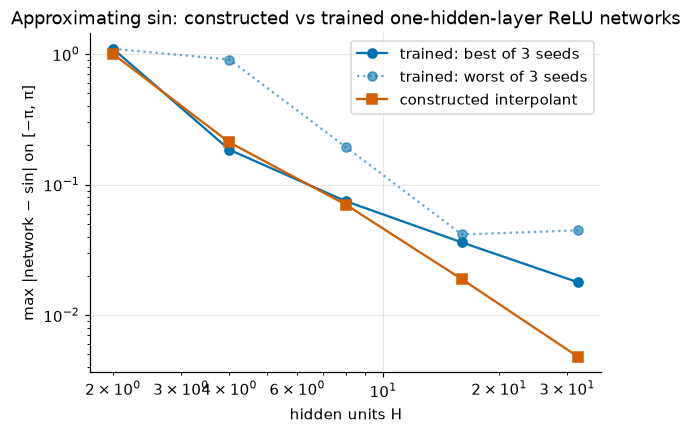

In [17]:
x_train = torch.linspace(-math.pi, math.pi, 200).unsqueeze(1)
y_train = torch.sin(x_train)
x_dense = torch.linspace(-math.pi, math.pi, 5001).unsqueeze(1)
y_dense = torch.sin(x_dense)


def interpolation_error(H):
    knots = torch.linspace(-math.pi, math.pi, H + 1, dtype=torch.float64)
    xd = x_dense.squeeze(1).double()
    idx = torch.searchsorted(knots, xd).clamp(1, H)
    x0, x1 = knots[idx - 1], knots[idx]
    t = (xd - x0) / (x1 - x0)
    interp = (1 - t) * torch.sin(x0) + t * torch.sin(x1)
    return (interp - torch.sin(xd)).abs().max().item()


widths = [2, 4, 8, 16, 32]
trained = {}
for H in widths:
    errors = []
    for seed in range(3):
        model = train_relu_net(H, x_train, y_train, steps=3000, seed=seed)
        with torch.no_grad():
            errors.append((model(x_dense) - y_dense).abs().max().item())
    trained[H] = errors
    print(f"H = {H:>2}: trained max errors {[f'{e:.4f}' for e in errors]}   constructed {interpolation_error(H):.4f}")

plt.loglog(widths, [min(trained[H]) for H in widths], "o-", label="trained: best of 3 seeds")
plt.loglog(widths, [max(trained[H]) for H in widths], "o:", color=COLORS[0], alpha=0.6, label="trained: worst of 3 seeds")
plt.loglog(widths, [interpolation_error(H) for H in widths], "s-", label="constructed interpolant")
plt.xlabel("hidden units H")
plt.ylabel("max |network − sin| on [−π, π]")
plt.title("Approximating sin: constructed vs trained one-hidden-layer ReLU networks")
plt.legend()
plt.show()

*Your answers:*

> **Worked solution.**
>
> 1. At small widths the best trained network roughly matches the construction (H = 4: 0.18 vs 0.21; H = 8: 0.075 vs 0.070) — training can even place its kinks better than equally spaced knots. As $H$ grows, the gap opens: at $H = 32$ the construction's error is about 0.005, while trained networks reach only 0.018–0.045. The construction follows the $1/H^2$ rate; the trained error falls much more slowly. With $H = 2$ neither does well: three knots at $-\pi, 0, \pi$ give the zero function, an error of 1.
> 2. A lot. At $H = 4$ one seed reaches 0.18 and the other two get stuck near 0.91; at $H = 32$ the worst seed is 2.5 times worse than the best. The result of training depends on the random initialization, so a fair statement about "a width-$H$ network" must report several seeds (Chapter 4, notebook 26).
> 3. Representation is an existence statement: good weights exist. This experiment shows that gradient descent, with a fixed budget of steps, does not reliably find them, and the shortfall grows with width. Training is an optimization problem in its own right — initialization, the optimizer, and the learning rate (Chapter 3) decide how much of a network's representational capacity is actually used.

## Problem 5: Independent capstone — can an untrained classifier beat ln K?

Test a diagnostic rather than accepting it as a rule. Use a simple balanced dataset: 80 equally spaced inputs in [-1, 1], with label 1 when x > 0. There is no training in this experiment.

**Before running:** predict how initial cross-entropy and accuracy vary with initialization scale, and whether one low loss proves leakage. Specify a negative control that breaks the input/label relationship.

Implement `initial_metrics(logits, labels)` returning scalar tensors `(mean_cross_entropy, accuracy)`. Verify it independently. Then design and implement the experiment from scratch: choose at least **three nonnegative scales including zero** and **30 seeds**. For each seed create `nn.Linear(1, 2)` after `torch.manual_seed(seed)`; multiply both its initial weight and bias by the scale without training. Compare the real labels with a shuffled copy, using one permutation from a local generator seeded with the same seed. Pair the model parameters across label conditions and scales so those comparisons have a control.

Store rows `(scale, seed, shuffled, loss, accuracy)` in a float64 tensor `study2`, where shuffled is 0 or 1. Design plots showing the distribution across seeds and report how often loss falls below ln 2 for each condition. Do not report only the best initialization. Include an explicit counterexample to the claim that a low initial loss necessarily proves a bug, and discuss why this unusually simple dataset limits the conclusion.

*Your predictions, controls, scale choices, and plots to produce (write before running):*

In [18]:
capstone_X = torch.linspace(-1, 1, 80).unsqueeze(1)  # (80, 1)
capstone_y = (capstone_X[:, 0] > 0).long()           # balanced (80,)

<details>
<summary><b>💡 Hint</b></summary>

Zero logits give uniform predictions and loss ln 2 exactly, for either labeling. Scaling changes confidence, while a random slope may already have the correct direction. Use the same parameters to compare genuine and shuffled labels; only change one factor at a time.

</details>

In [19]:
def initial_metrics(logits, labels):
    loss = F.cross_entropy(logits, labels)
    accuracy = (logits.argmax(dim=1) == labels).double().mean()
    return loss, accuracy

In [20]:
_test_logits = torch.tensor([[1000.0, -1000.0], [-1000.0, 1000.0], [0.0, 0.0]], dtype=torch.float64)
_test_labels = torch.tensor([0, 0, 1])
_loss, _accuracy = initial_metrics(_test_logits, _test_labels)
check_shape(_loss, (), "mean cross-entropy")
check_shape(_accuracy, (), "accuracy")
check_close(_loss, (2000 + math.log(2)) / 3, "stable mean loss on extreme logits")
check_close(_accuracy, 1 / 3, "argmax accuracy (ties choose class 0)")
_uniform_loss, _ = initial_metrics(torch.zeros(80, 2), capstone_y)
check_close(_uniform_loss, math.log(2), "uniform baseline")
_gen = torch.Generator().manual_seed(5)
for _n, _k in [(1, 2), (17, 4)]:
    _z = torch.randn(_n, _k, generator=_gen, dtype=torch.float64)
    _y = torch.randint(_k, (_n,), generator=_gen)
    _loss, _acc = initial_metrics(_z, _y)
    _reference = -torch.distributions.Categorical(logits=_z).log_prob(_y).mean()
    check_close(_loss, _reference, "mean loss vs categorical likelihood")
    check_close(_acc, (_z.argmax(dim=1) == _y).double().mean(), "accuracy on general logits")
passed("Capstone metrics")

✅ Capstone metrics passed


<details>
<summary><b>💡 Hint</b></summary>

Save every seed's two metrics, then aggregate or plot the records. Label permutations must preserve class counts. A spread or histogram is more informative here than a single average. Evaluate under torch.no_grad().

</details>

scale=0, true: accuracy mean 0.500, SD 0.000
scale=0, true: fraction below ln 2 (tolerance 1e-6) = 0.000
scale=0, shuffled: accuracy mean 0.500, SD 0.000
scale=0, shuffled: fraction below ln 2 (tolerance 1e-6) = 0.000
scale=0.01, true: accuracy mean 0.467, SD 0.196
scale=0.01, true: fraction below ln 2 (tolerance 1e-6) = 0.433
scale=0.01, shuffled: accuracy mean 0.504, SD 0.029
scale=0.01, shuffled: fraction below ln 2 (tolerance 1e-6) = 0.433
scale=1, true: accuracy mean 0.467, SD 0.196
scale=1, true: fraction below ln 2 (tolerance 1e-6) = 0.250
scale=1, shuffled: accuracy mean 0.504, SD 0.029
scale=1, shuffled: fraction below ln 2 (tolerance 1e-6) = 0.067
scale=10, true: accuracy mean 0.467, SD 0.196
scale=10, true: fraction below ln 2 (tolerance 1e-6) = 0.117
scale=10, shuffled: accuracy mean 0.504, SD 0.029
scale=10, shuffled: fraction below ln 2 (tolerance 1e-6) = 0.000


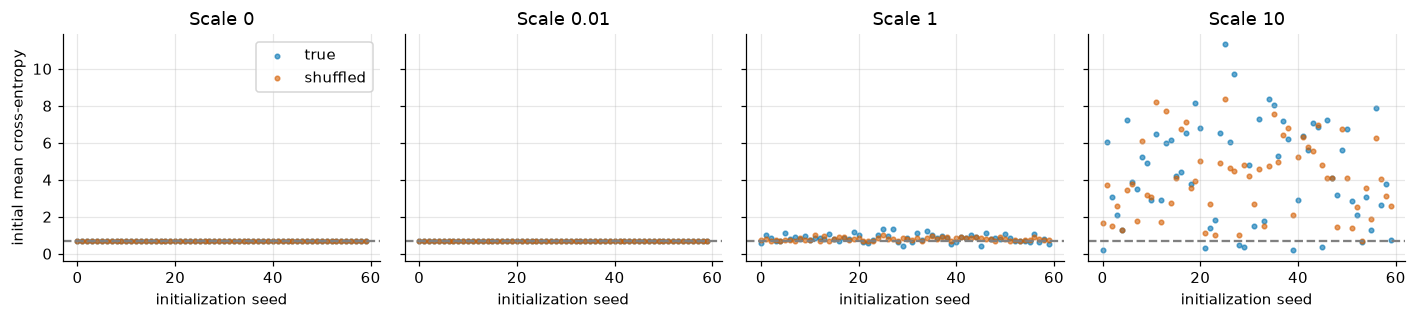

One untrained counterexample: [1.0, 0.0, 0.0, 0.5689132809638977, 0.925]


In [21]:
scales2, seeds2 = [0.0, 0.01, 1.0, 10.0], list(range(60))
records2 = []
for seed in seeds2:
    torch.manual_seed(seed)
    model = nn.Linear(1, 2)
    perm = torch.randperm(len(capstone_y), generator=torch.Generator().manual_seed(seed))
    with torch.no_grad():
        base_logits = model(capstone_X)
        for scale in scales2:
            for shuffled, labels in [(0, capstone_y), (1, capstone_y[perm])]:
                loss, accuracy = initial_metrics(scale * base_logits, labels)
                records2.append([scale, seed, shuffled, loss.item(), accuracy.item()])
study2 = torch.tensor(records2, dtype=torch.float64)
fig, axes = plt.subplots(1, len(scales2), figsize=(13, 3), sharey=True)
for ax, scale in zip(axes, scales2):
    for shuffled, label in [(0, "true"), (1, "shuffled")]:
        rows = study2[(study2[:, 0] == scale) & (study2[:, 2] == shuffled)]
        ax.scatter(rows[:, 1], rows[:, 3], s=9, alpha=0.6, label=label)
        print(f"scale={scale:g}, {label}: accuracy mean {rows[:, 4].mean().item():.3f}, SD {rows[:, 4].std().item():.3f}")
        print(f"scale={scale:g}, {label}: fraction below ln 2 (tolerance 1e-6) = {(rows[:, 3] < math.log(2) - 1e-6).double().mean().item():.3f}")
    ax.axhline(math.log(2), color="gray", ls="--")
    ax.set(xlabel="initialization seed", title=f"Scale {scale:g}")
axes[0].set_ylabel("initial mean cross-entropy")
axes[0].legend()
plt.tight_layout()
plt.show()
print("One untrained counterexample:", study2[(study2[:, 0] == 1) & (study2[:, 2] == 0) & (study2[:, 3] < 0.6)][0].tolist())

In [22]:
check_shape(study2, (len(study2), 5), "study2")
check(study2.dtype == torch.float64, "store study2 in float64")
check(bool(torch.isfinite(study2).all()), "all records must be finite")
_scales, _seeds = study2[:, 0].unique().tolist(), study2[:, 1].unique().tolist()
check(len(_scales) >= 3 and min(_scales) == 0, "include zero and at least two positive scales")
check(len(_seeds) >= 30 and all(s >= 0 and s == int(s) for s in _seeds), "use at least 30 nonnegative integer seeds")
check(len(study2) == len(_scales) * len(_seeds) * 2, "record both label controls for every scale and seed")
for _seed in _seeds:
    torch.manual_seed(int(_seed))
    _model = nn.Linear(1, 2)
    _perm = torch.randperm(80, generator=torch.Generator().manual_seed(int(_seed)))
    with torch.no_grad():
        _base = _model(capstone_X)
        for _scale in _scales:
            for _shuffled, _labels in [(0, capstone_y), (1, capstone_y[_perm])]:
                _rows = study2[(study2[:, 0] == _scale) & (study2[:, 1] == _seed) & (study2[:, 2] == _shuffled)]
                check(len(_rows) == 1, "record each condition exactly once")
                _logits = (_scale * _base).double()
                _loss = -(F.log_softmax(_logits, dim=1)[torch.arange(80), _labels]).mean()
                _acc = (_logits.argmax(dim=1) == _labels).double().mean()
                check_close(_rows[0, 3:], torch.stack([_loss, _acc]), "recorded metrics vs independent reference", rtol=1e-5, atol=1e-6)
passed("Capstone controlled experiment (written analysis still required)")

✅ Capstone controlled experiment (written analysis still required) passed


**Report rubric (address every item):** quantify the distributions, identify a counterexample by seed/scale/loss, compare real and shuffled labels, and explain the zero-scale control. State a revised diagnostic with its assumptions, one limitation, and a follow-up experiment. Code checks do not assess the quality of your plots or argument.

> **Worked solution.**
>
> With zero scale both labelings give ln 2 and accuracy 0.5: this verifies the baseline and class balance. Near zero scale probabilities remain nearly uniform, so losses cluster near ln 2. At larger scales a favorable random slope and modest bias can already classify the simple threshold task well; other seeds confidently favor the wrong class and give very large loss. The records and printed counterexample establish that low initial loss is possible without training or leakage. Shuffling preserves class counts but removes the systematic relationship to x; occasional below-baseline shuffled results can still occur by chance. A few favorable runs do not establish that an initialization is generally useful. The valid diagnostic is conditional: approximately uniform predictions imply a loss near ln K; substantial deviations call for inspecting logits, class balance, loss reduction, multiple seeds, and negative controls. They do not by themselves prove leakage. This one-dimensional, balanced task has unusually simple structure; repeat with larger, noisier, higher-dimensional data before drawing practical conclusions. The two controls share parameters, avoiding a confound from redrawing models when changing labels.